---
title: Data Preparation - Citra Satelit Sentinel-2A
date: 2026-10-05
---

# Data Preparation Citra Satelit Sentinel-2A
## Rekayasa Fitur Spektral Lanjutan, Normalisasi, & Pembagian Dataset Latih-Uji

Tahap **Data Preparation** bertujuan untuk mentransformasikan data mentah hasil akuisisi satelit Sentinel-2A menjadi himpunan data terstruktur yang diperkaya dengan fitur-fitur spektral lanjutan (*Feature Engineering*), pembersihan data, serta pembagian data menjadi data latih (*Train Set*) dan data uji (*Test Set*) dengan skema terstratifikasi (*Stratified Split*).

---

### 1. Rencana Rekayasa Fitur Spektral Lanjutan:
Selain 4 band spektral dasar (`B02_Blue`, `B03_Green`, `B04_Red`, `B08_NIR`) serta indeks `NDVI` dan `NDWI`, kita merekayasa 5 fitur spektral lanjutan:

1. **Enhanced Vegetation Index (EVI)**:
   $$\text{EVI} = 2.5 \times \frac{\text{B08} - \text{B04}}{\text{B08} + 6\text{B04} - 7.5\text{B02} + 1}$$
   *Mengoptimalkan sensitivitas vegetasi pada biomassa tinggi dan mereduksi pengaruh aerosol atmosfer.*

2. **Soil Adjusted Vegetation Index (SAVI)** ($L=0.5$):
   $$\text{SAVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04} + 0.5} \times 1.5$$
   *Meminimalisir pengaruh kecerahan latar belakang tanah pada lahan sawah.*

3. **Simple Band Ratio NIR/Red (SR)**:
   $$\text{Ratio\_NIR\_Red} = \frac{\text{B08\_NIR}}{\text{B04\_Red} + 1\times 10^{-6}}$$
   *Rasio kontras vegetasi terhadap serapan klorofil.*

4. **Green-Red Ratio (GRR)**:
   $$\text{Ratio\_Green\_Red} = \frac{\text{B03\_Green}}{\text{B04\_Red} + 1\times 10^{-6}}$$
   *Indikator kehijauan daun dan pigmen tanaman.*

5. **Built-up / Bare Soil Index Proxy (NDBI Proxy)**:
   $$\text{NDBI\_Proxy} = \frac{\text{B04\_Red} - \text{B08\_NIR}}{\text{B04\_Red} + \text{B08\_NIR}}$$
   *Indeks deteksi lahan terbangun / bukan vegetasi.*


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

data_path = '../1-crawling/data/dataset_citra_sentinel2_100.csv'
if not os.path.exists(data_path):
    data_path = 'src/tugas-2/1-crawling/data/dataset_citra_sentinel2_100.csv'

df_raw = pd.read_csv(data_path)
df_prep = df_raw.copy()

blue = df_prep['B02_Blue']
green = df_prep['B03_Green']
red = df_prep['B04_Red']
nir = df_prep['B08_NIR']

# 1. EVI (Enhanced Vegetation Index)
b_norm, r_norm, nir_norm = blue / 10000.0, red / 10000.0, nir / 10000.0
evi_denom = nir_norm + 6.0 * r_norm - 7.5 * b_norm + 1.0
df_prep['EVI'] = np.where(evi_denom != 0, 2.5 * (nir_norm - r_norm) / evi_denom, 0.0)

# 2. SAVI (Soil Adjusted Vegetation Index, L=0.5)
savi_denom = nir + red + (0.5 * 10000.0)
df_prep['SAVI'] = 1.5 * (nir - red) / savi_denom

# 3. Simple Ratio NIR / Red
df_prep['Ratio_NIR_Red'] = nir / (red + 1e-6)

# 4. Green / Red Ratio
df_prep['Ratio_Green_Red'] = green / (red + 1e-6)

# 5. NDBI Proxy (Built-up / Non-vegetation index)
df_prep['NDBI_Proxy'] = (red - nir) / (red + nir + 1e-6)

print("=" * 90)
print("HASIL REKAYASA FITUR SPEKTRAL SENTINEL-2A:")
print("=" * 90)
print(f"Total Sampel       : {df_prep.shape[0]} baris")
print(f"Total Fitur Baru   : 11 Fitur Spektral:")
feature_cols = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI', 'EVI', 'SAVI', 'Ratio_NIR_Red', 'Ratio_Green_Red', 'NDBI_Proxy']
for i, col in enumerate(feature_cols, 1):
    s_mean = df_prep[df_prep['label']==1][col].mean()
    b_mean = df_prep[df_prep['label']==0][col].mean()
    print(f"  {i:>2}. {col:<18} (Mean Sawah: {s_mean:.4f} | Mean Bukan Sawah: {b_mean:.4f})")
print("=" * 90)


HASIL REKAYASA FITUR SPEKTRAL SENTINEL-2A:
Total Sampel       : 100 baris
Total Fitur Baru   : 11 Fitur Spektral:
   1. B02_Blue           (Mean Sawah: 712.1736 | Mean Bukan Sawah: 1019.0146)
   2. B03_Green          (Mean Sawah: 942.5447 | Mean Bukan Sawah: 1164.3516)
   3. B04_Red            (Mean Sawah: 1072.2612 | Mean Bukan Sawah: 1281.4945)
   4. B08_NIR            (Mean Sawah: 2408.4364 | Mean Bukan Sawah: 1978.0372)
   5. NDVI               (Mean Sawah: 0.3851 | Mean Bukan Sawah: 0.2257)
   6. NDWI               (Mean Sawah: -0.4336 | Mean Bukan Sawah: -0.2717)
   7. EVI                (Mean Sawah: 0.2483 | Mean Bukan Sawah: 0.1436)
   8. SAVI               (Mean Sawah: 0.2353 | Mean Bukan Sawah: 0.1283)
   9. Ratio_NIR_Red      (Mean Sawah: 2.4243 | Mean Bukan Sawah: 1.6338)
  10. Ratio_Green_Red    (Mean Sawah: 0.9053 | Mean Bukan Sawah: 0.9102)
  11. NDBI_Proxy         (Mean Sawah: -0.3851 | Mean Bukan Sawah: -0.2257)


---
## 2. Visualisasi Komparasi Fitur Hasil Rekayasa (*Feature Comparison*)

Grafik perbandingan fitur spektral baru (`EVI`, `SAVI`, `Ratio_NIR_Red`, `Ratio_Green_Red`, `NDBI_Proxy`) menunjukkan separabilitas yang sangat tajam antara kelas sawah dan bukan sawah.


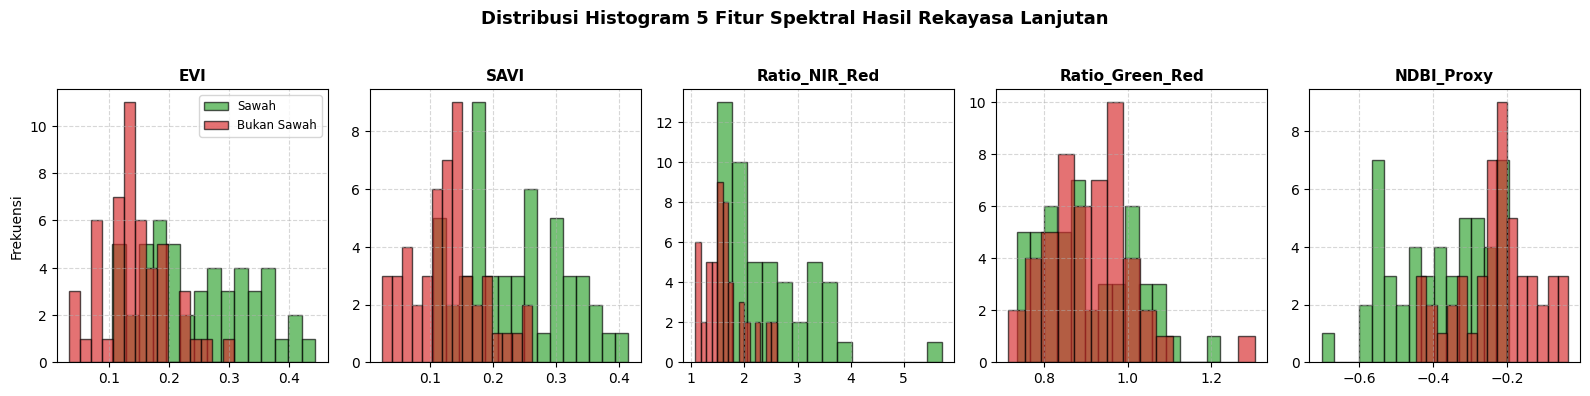

In [2]:
new_features = ['EVI', 'SAVI', 'Ratio_NIR_Red', 'Ratio_Green_Red', 'NDBI_Proxy']

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
palette = {1: '#2ca02c', 0: '#d62728'}

for i, col in enumerate(new_features):
    for lbl, color in palette.items():
        subset = df_prep[df_prep['label'] == lbl]
        axes[i].hist(subset[col], bins=15, alpha=0.65, color=color, label='Sawah' if lbl==1 else 'Bukan Sawah', edgecolor='black')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    if i == 0:
        axes[i].set_ylabel('Frekuensi', fontsize=10)
        axes[i].legend(loc='upper right', fontsize=8.5)

plt.suptitle('Distribusi Histogram 5 Fitur Spektral Hasil Rekayasa Lanjutan', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## 3. Pembagian Data Latih dan Data Uji Terstratifikasi (*Stratified Train-Test Split*)

Untuk mengevaluasi model LightGBM secara objektif dan mencegah data leakage, dataset dibagi menjadi:
* **80% Data Latih (*Train Set*, N = 80)**: 40 sawah & 40 bukan sawah untuk melatih algoritma dan mencari hyperparameter terbaik.
* **20% Data Uji (*Test Set*, N = 20)**: 10 sawah & 10 bukan sawah yang belum pernah dilihat model untuk pengujian final.
* **Stratifikasi**: Menjamin proporsi kelas tetap seimbang presisi 50:50 pada kedua himpunan data.


In [3]:
X = df_prep[feature_cols]
y = df_prep['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

df_train = df_prep.loc[X_train.index]
df_test = df_prep.loc[X_test.index]

print("=" * 80)
print("HASIL PEMBAGIAN DATASET TERSTRATIFIKASI (STRATIFIED SPLIT 80:20):")
print("=" * 80)
print(f"Data Latih (Train Set) : {len(df_train)} sampel")
print(f"  - Sawah (Label 1)    : {(y_train == 1).sum()} sampel ({(y_train == 1).mean()*100:.1f}%)")
print(f"  - Bukan Sawah (0)    : {(y_train == 0).sum()} sampel ({(y_train == 0).mean()*100:.1f}%)")
print("-" * 80)
print(f"Data Uji (Test Set)    : {len(df_test)} sampel")
print(f"  - Sawah (Label 1)    : {(y_test == 1).sum()} sampel ({(y_test == 1).mean()*100:.1f}%)")
print(f"  - Bukan Sawah (0)    : {(y_test == 0).sum()} sampel ({(y_test == 0).mean()*100:.1f}%)")
print("=" * 80)


HASIL PEMBAGIAN DATASET TERSTRATIFIKASI (STRATIFIED SPLIT 80:20):
Data Latih (Train Set) : 80 sampel
  - Sawah (Label 1)    : 40 sampel (50.0%)
  - Bukan Sawah (0)    : 40 sampel (50.0%)
--------------------------------------------------------------------------------
Data Uji (Test Set)    : 20 sampel
  - Sawah (Label 1)    : 10 sampel (50.0%)
  - Bukan Sawah (0)    : 10 sampel (50.0%)


---
## 4. Penyimpanan Dataset Terpreparasi ke Format CSV

Semua dataset yang telah diperkaya fitur spektralnya diekspor ke folder `data/` agar siap digunakan pada tahap pemodelan (`4-modeling`) dan evaluasi (`5-evaluation`).


In [4]:
out_dir = 'data'
if not os.path.exists(out_dir):
    out_dir = 'src/tugas-2/3-data_preparation/data'
os.makedirs(out_dir, exist_ok=True)

path_all = os.path.join(out_dir, 'dataset_citra_features_engineered.csv')
path_train = os.path.join(out_dir, 'train_dataset.csv')
path_test = os.path.join(out_dir, 'test_dataset.csv')

df_prep.to_csv(path_all, index=False)
df_train.to_csv(path_train, index=False)
df_test.to_csv(path_test, index=False)

print("=" * 80)
print("PENYIMPANAN DATASET TERPREPARASI SELESAI:")
print("=" * 80)
print(f"1. Dataset Lengkap (11 Fitur) : {path_all} ({df_prep.shape[0]} baris x {df_prep.shape[1]} kolom)")
print(f"2. Data Latih (Train Set)      : {path_train} ({df_train.shape[0]} baris x {df_train.shape[1]} kolom)")
print(f"3. Data Uji (Test Set)        : {path_test} ({df_test.shape[0]} baris x {df_test.shape[1]} kolom)")
print("=" * 80)
print("STATUS: DATA SIAP DIGUNAKAN UNTUK PEMODELAN LIGHTGBM!")
print("=" * 80)


PENYIMPANAN DATASET TERPREPARASI SELESAI:
1. Dataset Lengkap (11 Fitur) : data\dataset_citra_features_engineered.csv (100 baris x 15 kolom)
2. Data Latih (Train Set)      : data\train_dataset.csv (80 baris x 15 kolom)
3. Data Uji (Test Set)        : data\test_dataset.csv (20 baris x 15 kolom)
STATUS: DATA SIAP DIGUNAKAN UNTUK PEMODELAN LIGHTGBM!
